# Error de medida: corrección, selección y fallos
## Resumen
Recuperación de la idea26oct, reconstruida y ejecutada27oct; no se presenta como nueva investigación27. Con n2000 y varianza correcta, RMSE cae a≈.101 frente a≈.560 de OLSproxy. Con n100 empeora a≈.951 frente a≈.570 y se abstiene15veces.
## Contexto y métodos
$X=.8Z+u$, $Y=\beta X+.8Z+e$, $W=Z+v$, con $Var(v)=\tau^2$ conocida externamente, v independiente de(X,Z,Y).
$$C=\begin{pmatrix}S_{XX}&S_{XW}\\ S_{WX}&S_{WW}-\tau^2\end{pmatrix},\qquad \hat\theta=C^{-1}(S_{XY},S_{WY})^T.$$
La primera coordenada estimaβ bajo estos supuestos; no reutilizamos F ni emitimos CI causales sin derivarlos. Una matriz muestral corregida puede no ser definida positiva.
### Supuestos clave
Varianza conocida de una fuente externa, modelo clásico lineal y covarianza válida. Se exige positividad y condición de la correlación corregida<=100. El gate es invariante a unidades, pero no valida la verdad del supuesto.
## Datos
Semilla20261026,200 réplicas por n/β, tamaños100/500/2000, β0/.3, varianzas declaradas0/.5/1/1.5, verdadera1. Son1200datasets y4800evaluaciones pareadas.

In [1]:
import json,csv
from pathlib import Path
from IPython.display import display,Image
summary=json.loads(Path('results/summary.json').read_text())
summary['config']

Out[0]: 
{'seed': 20261026,
 'sample_sizes': [100, 500, 2000],
 'replicates': 200,
 'effects': [0.0, 0.3],
 'true_noise_variance': 1.0,
 'assumed_noise_variances': [0.0, 0.5, 1.0, 1.5],
 'max_condition': 100.0,
 'hypothesis': {'known_variance_abs_bias_n2000_max': 0.04,
  'known_variance_acceptance_n2000_min': 0.95,
  'known_variance_rmse_vs_proxy_n2000_max_ratio': 0.5},
 'comparison': 'same accepted replicates, abstentions separately reported'}


## Resultados
Se comparan errores solo sobre las mismas réplicas aceptadas, informando aparte abstenciones. No equivale a riesgo operacional incondicional.

In [2]:
summary['n2000']

Out[0]: 
[{'n': 2000,
  'effect': 0.0,
  'assumed_variance': 0.0,
  'accepted': 200,
  'replicates': 200,
  'acceptance': 1.0,
  'bias_accepted': 0.5595434219954988,
  'rmse_accepted': 0.5598726694311495,
  'naive_rmse_matched': 0.5598726694311495,
  'oracle_rmse_matched': 0.02069513234873075,
  'median_seconds': 0.0003534625000156666,
  'max_python_bytes': 145512},
 {'n': 2000,
  'effect': 0.0,
  'assumed_variance': 0.5,
  'accepted': 200,
  'replicates': 200,
  'acceptance': 1.0,
  'bias_accepted': 0.45871695612517427,
  'rmse_accepted': 0.4593853734983091,
  'naive_rmse_matched': 0.5598726694311495,
  'oracle_rmse_matched': 0.02069513234873075,
  'median_seconds': 0.0003349700000114808,
  'max_python_bytes': 145480},
 {'n': 2000,
  'effect': 0.0,
  'assumed_variance': 1.0,
  'accepted': 200,
  'replicates': 200,
  'acceptance': 1.0,
  'bias_accepted': -0.007857383397787639,
  'rmse_accepted': 0.10081525009143791,
  'naive_rmse_matched': 0.5598726694311495,
  'oracle_rmse_matched': 0

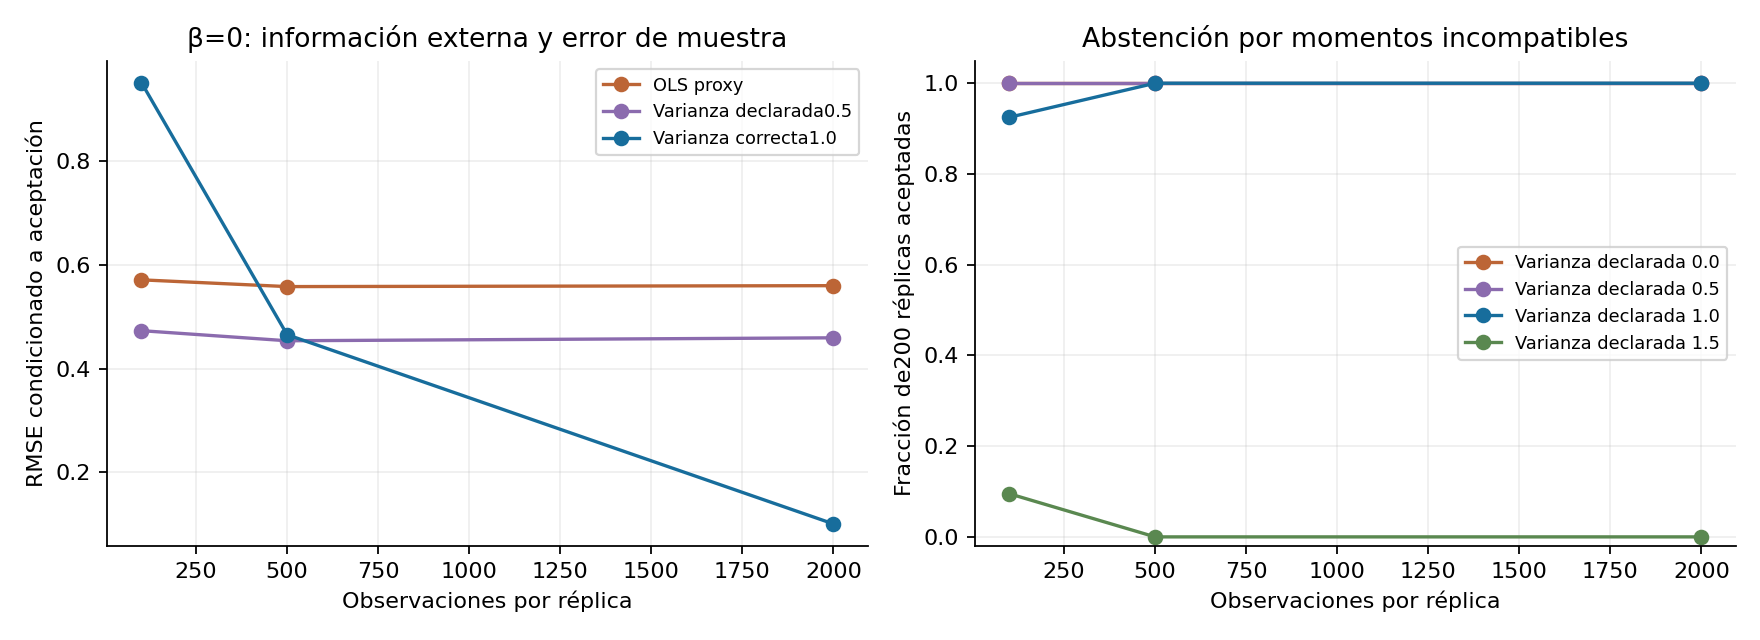

In [3]:
display(Image(filename='results/audit.png'))

### Fallos observados
Poca muestra amplifica el error al invertir momentos. Varianza incorrecta puede producir sesgo grave aunque el gate acepte. El oráculo Z observado dispone de información adicional.

In [4]:
rows=list(csv.DictReader(Path('results/summary.csv').open()))
[r for r in rows if r['effect']=='0.0' and r['n']=='100']

Out[0]: 
[{'n': '100',
  'effect': '0.0',
  'assumed_variance': '0.0',
  'accepted': '200',
  'replicates': '200',
  'acceptance': '1.0',
  'bias_accepted': '0.5651217450060906',
  'rmse_accepted': '0.5710901356379057',
  'naive_rmse_matched': '0.5710901356379058',
  'oracle_rmse_matched': '0.10923147413620822',
  'median_seconds': '0.0003648944999952164',
  'max_python_bytes': '9099'},
 {'n': '100',
  'effect': '0.0',
  'assumed_variance': '0.5',
  'accepted': '200',
  'replicates': '200',
  'acceptance': '1.0',
  'bias_accepted': '0.46129175662003336',
  'rmse_accepted': '0.4731502156415056',
  'naive_rmse_matched': '0.5710901356379058',
  'oracle_rmse_matched': '0.10923147413620822',
  'median_seconds': '0.00033959200001731915',
  'max_python_bytes': '8696'},
 {'n': '100',
  'effect': '0.0',
  'assumed_variance': '1.0',
  'accepted': '185',
  'replicates': '200',
  'acceptance': '0.925',
  'bias_accepted': '-0.2570706724541218',
  'rmse_accepted': '0.9511855075630156',
  'naive_rmse

## Comprobaciones
Oráculos poblacionales, OLS independiente cuandoτ²declarada0, invariancia afín y linealidad en Y, rechazo de entradas inválidas y abstención numérica.

In [5]:
from src.moments import correct_covariance,population_covariance
known=correct_covariance(population_covariance(.3),1)
wrong=correct_covariance(population_covariance(.3),.5)
assert abs(known.slope-.3)<1e-12
assert abs(wrong.slope-.3)>.4
assert all(summary['checks'].values())
print(known,wrong)

Estimate(slope=0.2999999999999999, status='accepted', condition=12.157747924516235) Estimate(slope=0.7604316546762592, status='accepted', condition=5.501690937160594)


## Conclusiones
La información externa puede identificar una corrección consistente, pero no elimina error de muestra ni arregla supuestos falsos. ComponenteS2 sintético; fuentes, derivación, alcance y14puntos en informe.md. Outputs regenerados27; no se restauraron byteporbyte los del26.